# Tarea 4 · Una red neuronal con nuestros datos: ENLA 2024, 6.° de primaria

**Análisis de Datos con IA Aplicada · DESPUÉS de las sesiones 5 y 6**
Docente: Doris Elena Campo Duarte · Escuela de Posgrado, Universidad Peruana Unión
Equipo: María del Pilar Mori Sánchez y Boris Jesús Arce Saavedra

<a href="https://colab.research.google.com/github/mmoris-code/DATASET_ENLA_6_2024/blob/main/notebooks/S56_red_con_mis_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

**Qué hacemos.** Repetimos el laboratorio 1 (una red sin freno y otra con freno) con los datos de nuestra investigación, probamos cuatro redes, elegimos la mejor con los quices (validación) y solo al final presentamos el examen final (prueba) junto a Elastic Net y Random Forest.

**Nuestros datos.** Archivo `enla6p_2024_modelado_mat.csv`, generado en el repositorio con `R/02_dataset_modelado.R` a partir del dataset curado de la Unidad I (base muestral de la ENLA 2024, MINEDU-UMC). Una fila por estudiante con medida observada en Matemática (103 522 casos). La variable que predecimos es `logro_mat` (Satisfactorio / No satisfactorio). Los predictores son contextuales y se conocen antes de la evaluación: gestión, área, sexo, DRE, número de evaluados de la IE y de la sección. No contiene nombres, DNI ni códigos modulares; `id_ie` es un código anonimizado por el MINEDU y se excluye del modelo.

**Ajustes respecto del cuaderno original (declarados).**
1. El archivo se lee directamente desde el repositorio público, sin subirlo al panel Archivos.
2. Se agregó una quinta línea editable, `LOTE = 256` (tamaño del lote). El original usa 32, pensado para 319 casos de estudio; con 58 216 casos de estudio, un lote de 32 hace que la red sin freno tarde de 15 a 20 minutos. Con 256 se mantienen unas 228 actualizaciones de pesos por época y el tiempo baja a menos de cinco minutos.

Ejecuta las celdas en orden (Entorno de ejecución → Ejecutar todo). Tarda unos 8 a 10 minutos.

## R1 · Cargar y preparar los datos

Lee el archivo, convierte `logro_mat` en 1 (Satisfactorio) y 0 (No satisfactorio) y separa los casos en tres grupos: para estudiar (entrenamiento), para los quices (validación) y para el examen final (prueba, 25 %). El relleno de vacíos y la escala se ajustan solo con los casos de estudio, para evitar la fuga de información.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
SEMILLA = 2026

# ======== CAMBIA SOLO ESTAS LÍNEAS ========
ARCHIVO   = ("https://raw.githubusercontent.com/mmoris-code/DATASET_ENLA_6_2024/"
             "main/data/processed/enla6p_2024_modelado_mat.csv")   # ENLA 2024, 6.° primaria
RESPUESTA = "logro_mat"          # logro en Matemática
POSITIVO  = "Satisfactorio"      # lo que queremos detectar
EXCLUIR   = ["id_ie"]            # código anonimizado de la IE: no es predictor
LOTE      = 256                  # tamaño del lote (el original usa 32; ver nota inicial)
# ==========================================

df = pd.read_csv(ARCHIVO).dropna(subset=[RESPUESTA])
if str(POSITIVO) not in df[RESPUESTA].astype(str).unique():
    raise ValueError(f"No encuentro «{POSITIVO}» en {RESPUESTA}. Sus valores son: "
                     f"{list(df[RESPUESTA].astype(str).unique()[:10])}")
y = (df[RESPUESTA].astype(str) == str(POSITIVO)).astype(int)
quitar = [RESPUESTA] + [c for c in EXCLUIR if c in df.columns]
X = pd.get_dummies(df.drop(columns=quitar), drop_first=True, dtype=float)   # texto -> 0/1
print(f"{len(df)} casos · {X.shape[1]} variables · {y.sum()} casos «{POSITIVO}» ({y.mean():.0%})")

X_train, X_test, y_train, y_test = train_test_split(        # examen final: 25 %
    X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
X_ent, X_val, y_ent, y_val = train_test_split(              # quices: 25 % del resto
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEMILLA)

relleno = SimpleImputer(strategy="median").fit(X_ent)       # rellena vacíos
escala = StandardScaler().fit(relleno.transform(X_ent))     # misma escala, sin trampa
prep = lambda A: escala.transform(relleno.transform(A))
X_ent_s, X_val_s, X_test_s, X_train_s = prep(X_ent), prep(X_val), prep(X_test), prep(X_train)
print("Estudia:", len(y_ent), "| Quices:", len(y_val), "| Examen final:", len(y_test))

103522 casos · 30 variables · 14886 casos «Satisfactorio» (14%)


Estudia: 58230 | Quices: 19411 | Examen final: 25881


✍️ **Anotamos:** casos, variables y porcentaje de positivos → ver la respuesta al final de la sección R4.

## R2 · Dos redes con nuestros datos: sin freno y con freno

La red grande (128 y 64 neuronas) entrena 300 épocas sin dropout ni parada temprana; la red pequeña (16 y 8 neuronas) usa dropout de 0,3 y parada temprana con paciencia de 20 épocas.

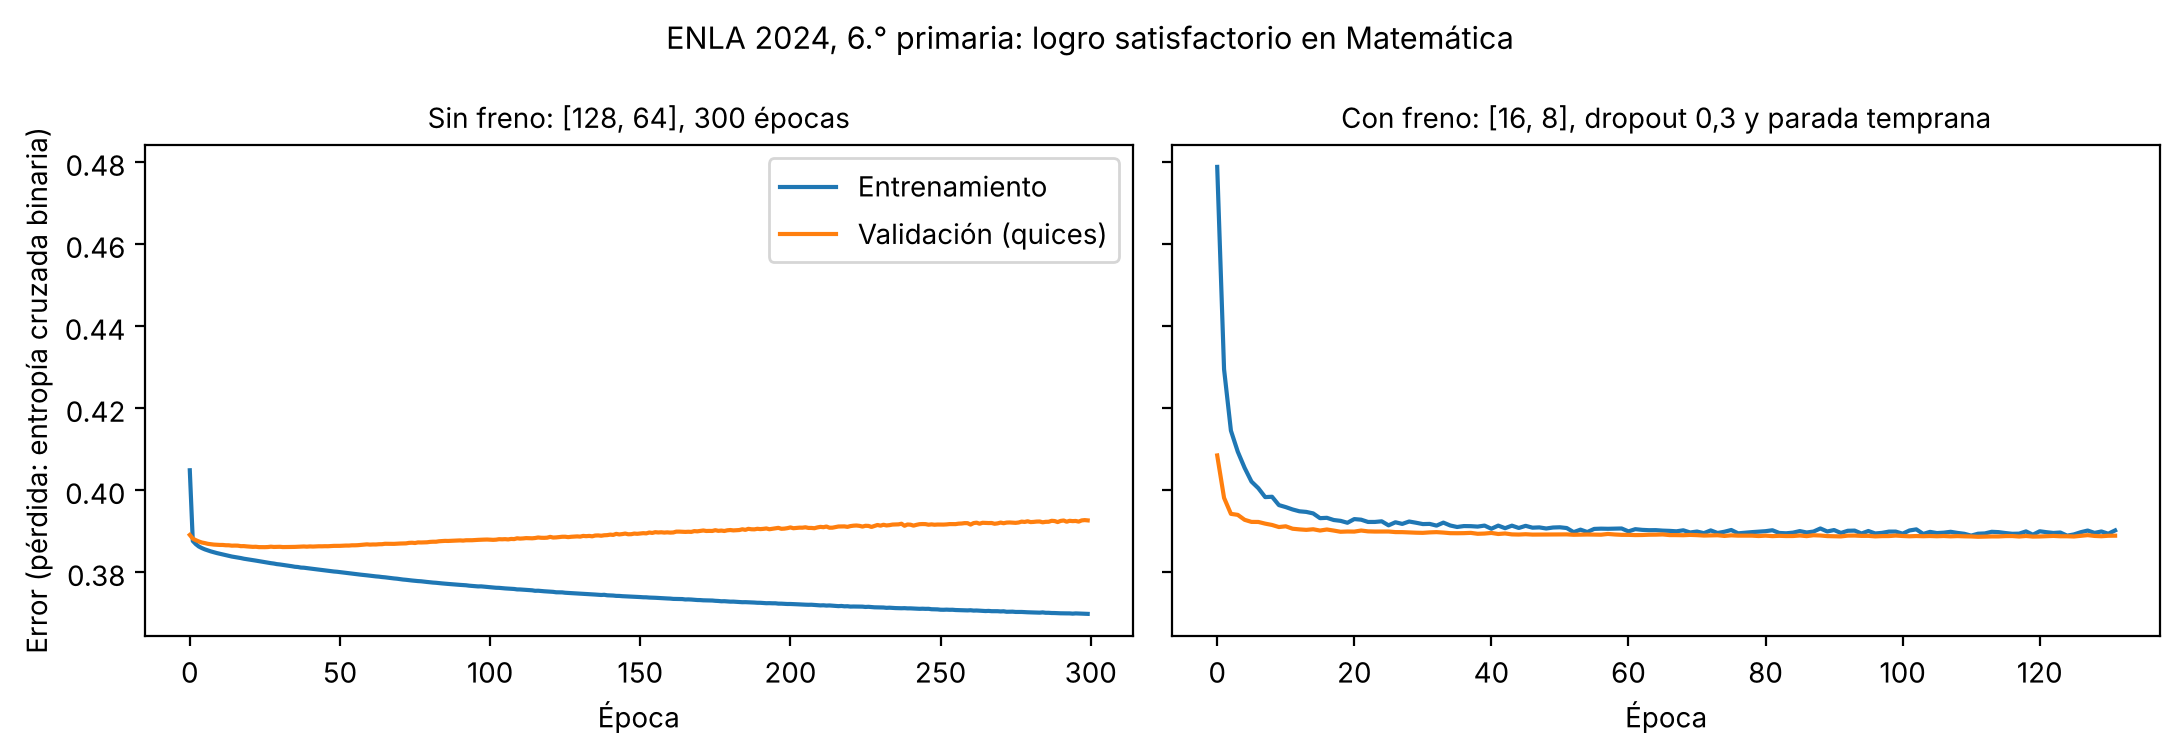

Sin freno: mejor época 25 de 300
Con freno: se detuvo en la época 132


In [2]:
def entrenar(neuronas, freno, dropout=0.3, tasa=0.001):
    keras.utils.set_random_seed(SEMILLA)
    capas = [keras.Input(shape=(X_ent_s.shape[1],))]
    for n in neuronas:
        capas.append(keras.layers.Dense(n, activation="relu"))
        if freno: capas.append(keras.layers.Dropout(dropout))          # freno 1
    capas.append(keras.layers.Dense(1, activation="sigmoid"))
    red = keras.Sequential(capas)
    red.compile(optimizer=keras.optimizers.Adam(tasa), loss="binary_crossentropy")
    parar = [keras.callbacks.EarlyStopping(patience=20,                  # freno 2
             restore_best_weights=True)] if freno else []
    h = red.fit(X_ent_s, y_ent, validation_data=(X_val_s, y_val), epochs=300,
                batch_size=LOTE, verbose=0, callbacks=parar)
    return red, h

red_sin, h_sin = entrenar([128, 64], freno=False)
red_con, h_con = entrenar([16, 8], freno=True)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for eje, h, titulo in [(ejes[0], h_sin, "Sin freno: [128, 64], 300 épocas"),
                       (ejes[1], h_con, "Con freno: [16, 8], dropout 0,3 y parada temprana")]:
    eje.plot(h.history["loss"], label="Entrenamiento")
    eje.plot(h.history["val_loss"], label="Validación (quices)")
    eje.set_title(titulo, fontsize=10); eje.set_xlabel("Época")
ejes[0].set_ylabel("Error (pérdida: entropía cruzada binaria)"); ejes[0].legend()
fig.suptitle("ENLA 2024, 6.° primaria: logro satisfactorio en Matemática", fontsize=11)
plt.tight_layout(); plt.show()
print("Sin freno: mejor época", int(np.argmin(h_sin.history["val_loss"])) + 1, "de 300")
print("Con freno: se detuvo en la época", len(h_con.history["loss"]))

✍️ **Anotamos:** Sí. La red sin freno ([128, 64], 300 épocas) alcanzó su menor error en los quices en la **época 25**; desde ahí, el error de validación sube lentamente (de 0,386 a 0,393) mientras el de entrenamiento sigue bajando hasta 0,370: empieza a memorizar. La red con freno ([16, 8], dropout 0,3) se detuvo en la **época 132** y sus dos curvas quedan juntas, cerca de 0,389. El patrón se parece al de la clase, pero la separación es menor: con 58 230 casos de estudio y 30 variables hay poco que memorizar.

## R3 · Nuestro experimento: cuatro redes, elegidas con los quices

Elegimos la red por su AUC en los quices (validación), no en el examen final. Si hay empate, el cuaderno prefiere la más sencilla (parsimonia).

In [3]:
pruebas = [   # cada línea es una red distinta
    {"neuronas": [16, 8],  "dropout": 0.3, "tasa": 0.001},
    {"neuronas": [32, 16], "dropout": 0.3, "tasa": 0.001},
    {"neuronas": [16, 8],  "dropout": 0.5, "tasa": 0.001},
    {"neuronas": [8],      "dropout": 0.2, "tasa": 0.01},
]
filas = []
for i, p in enumerate(pruebas, 1):
    red, h = entrenar(p["neuronas"], True, p["dropout"], p["tasa"])
    nota = roc_auc_score(y_val, red.predict(X_val_s, verbose=0).ravel())   # nota en quices
    filas.append({"Prueba": i, "Neuronas": p["neuronas"], "Dropout": p["dropout"],
                  "Tasa": p["tasa"], "Épocas": len(h.history["loss"]),
                  "AUC en quices": round(nota, 3)})
resultados = pd.DataFrame(filas)
resultados["Total de neuronas"] = [sum(p["neuronas"]) for p in pruebas]
# la mejor nota en los quices; si hay empate, la más sencilla (parsimonia)
orden = resultados.sort_values(["AUC en quices", "Total de neuronas"], ascending=[False, True])
elegida = pruebas[int(orden.index[0])]
print(resultados.drop(columns="Total de neuronas").to_string(index=False))
print("\nRed elegida con los quices (no con el examen):", elegida)

 Prueba Neuronas  Dropout  Tasa  Épocas  AUC en quices
      1  [16, 8]      0.3 0.001     132          0.674
      2 [32, 16]      0.3 0.001     152          0.679
      3  [16, 8]      0.5 0.001     107          0.669
      4      [8]      0.2 0.010      51          0.675

Red elegida con los quices (no con el examen): {'neuronas': [32, 16], 'dropout': 0.3, 'tasa': 0.001}


✍️ **Pensamos:** Las cuatro notas son casi iguales: AUC en quices entre 0,669 y 0,679 (rango de 0,010). El cuaderno eligió la red [32, 16] con dropout 0,3 y tasa 0,001 (0,679). La diferencia con la más sencilla ([8], 0,675) es del mismo orden que la variación entre pliegues de la tarea 1 (± 0,003), de modo que por parsimonia la red de 8 neuronas sería igual de defendible.

## R4 · El examen final: nuestras redes frente a Elastic Net y Random Forest

Todos presentan el examen final una sola vez, con los mismos casos. Se cuentan los dos tipos de error con el umbral 0,5 y, como agregado nuestro, con un umbral igual a la proporción de positivos en el entrenamiento, porque con datos desbalanceados el umbral 0,5 casi no detecta positivos.

In [4]:
red_mejor, _ = entrenar(elegida["neuronas"], True, elegida["dropout"], elegida["tasa"])
en = LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=0.5,
                        max_iter=5000).fit(X_train_s, y_train)
rf = RandomForestClassifier(n_estimators=300, random_state=SEMILLA).fit(X_train_s, y_train)

probas = {"Elastic Net": en.predict_proba(X_test_s)[:, 1],
          "Random Forest": rf.predict_proba(X_test_s)[:, 1],
          "Red sin freno": red_sin.predict(X_test_s, verbose=0).ravel(),
          "Red con freno": red_con.predict(X_test_s, verbose=0).ravel(),
          "Red elegida": red_mejor.predict(X_test_s, verbose=0).ravel()}
filas = []
for nombre, p in probas.items():
    tn, fp, fn, tp = confusion_matrix(y_test, (p >= 0.5).astype(int), labels=[0, 1]).ravel()
    filas.append({"Modelo": nombre, "AUC en examen final": round(roc_auc_score(y_test, p), 3),
                  f"«{POSITIVO}» no detectados": fn, "Falsas alarmas": fp})
final = pd.DataFrame(filas)
print(final.to_string(index=False))
print(f"\nEn el examen hay {int(y_test.sum())} casos «{POSITIVO}» y {int((y_test == 0).sum())} que no lo son.")

       Modelo  AUC en examen final  «Satisfactorio» no detectados  Falsas alarmas
  Elastic Net                0.676                           3704              20
Random Forest                0.678                           3384             548
Red sin freno                0.668                           3628             148
Red con freno                0.676                           3722               0
  Red elegida                0.679                           3722               0

En el examen hay 3722 casos «Satisfactorio» y 22159 que no lo son.


In [5]:
# Agregado: con datos desbalanceados, el umbral 0,5 casi no detecta positivos.
# Umbral alternativo = proporción de positivos en el entrenamiento (fijado sin mirar el examen).
umbral = float(y_train.mean())
filas = []
for nombre, p in probas.items():
    tn, fp, fn, tp = confusion_matrix(y_test, (p >= umbral).astype(int), labels=[0, 1]).ravel()
    filas.append({"Modelo": nombre, "Umbral": round(umbral, 3),
                  f"«{POSITIVO}» no detectados": fn, "Falsas alarmas": fp,
                  "Sensibilidad": round(tp / (tp + fn), 3), "Especificidad": round(tn / (tn + fp), 3)})
print(pd.DataFrame(filas).to_string(index=False))

       Modelo  Umbral  «Satisfactorio» no detectados  Falsas alarmas  Sensibilidad  Especificidad
  Elastic Net   0.144                           1299            8842         0.651          0.601
Random Forest   0.144                           1373            7949         0.631          0.641
Red sin freno   0.144                           1354            8527         0.636          0.615
Red con freno   0.144                           1061           10182         0.715          0.541
  Red elegida   0.144                           1100            9828         0.704          0.556


✍️ **Para nuestro artículo:** La red **no** le gana a Elastic Net por más que la variación: la red elegida obtiene 0,679 y Elastic Net 0,676 en el examen final, una diferencia de 0,003, igual al ± 0,003 de Elastic Net en la tarea 1. Es un empate, y nos quedamos con Elastic Net porque explica el peso de cada variable.

Con el umbral 0,5 ningún modelo sirve en la práctica: la clase positiva es solo el 14 %, las probabilidades predichas casi nunca superan 0,5 y la red elegida no detecta ninguno de los 3 722 estudiantes con logro satisfactorio. Con un umbral de 0,144 (proporción de positivos en el entrenamiento), la red elegida detecta el 70 % con especificidad de 0,56 y Elastic Net el 65 % con 0,60: el umbral cambia el punto de operación, no la capacidad de discriminar.

¿Qué error es más grave? Si el modelo se usara para focalizar apoyo pedagógico, lo más costoso es la **falsa alarma** en esta codificación: predecir «Satisfactorio» para un estudiante que no lo alcanza lo dejaría fuera del apoyo. Con un AUC cercano a 0,68, el modelo no debe usarse para decisiones sobre estudiantes individuales.

## Para cerrar

✍️ **En una frase:** Con nuestros datos no vale la pena una red neuronal: empata con Elastic Net (AUC 0,679 frente a 0,676 en el examen final), es más difícil de explicar y ninguno de los cinco modelos comparados aquí llega a 0,70, porque los seis predictores contextuales disponibles explican poco del logro en Matemática; nos quedamos con Elastic Net.

**Uso de IA generativa.** Claude (Anthropic) adaptó la configuración del cuaderno a nuestros datos, propuso el ajuste del tamaño del lote y el umbral alternativo, y redactó un primer borrador de las respuestas ✍️. Los autores ejecutamos el cuaderno, verificamos cada cifra con la salida y asumimos la responsabilidad del contenido.